In [40]:
import numpy as np

a = np.array([1,2,3])
b = np.array([4,5,6])


c = a + b
print(c)


c = a - b
print(c)

c = a * b
print(c)

c = a / b
print(c)

# dot or inner
c = a @ b
print(c)

# norm  or 欧氏距离
np.linalg.norm(a)

# cos
cos_theta = (a @ b) / (np.linalg.norm(a) * np.linalg.norm(b))
print(cos_theta)

# project a->b
proj = (a @ b) / (b @ b) * b
print(proj)

# 线性组合
alpha, beta = 2, -1
c = alpha * a + beta * b
print(c)

[5 7 9]
[-3 -3 -3]
[ 4 10 18]
[0.25 0.4  0.5 ]
32
0.9746318461970762
[1.66233766 2.07792208 2.49350649]
[-2 -1  0]


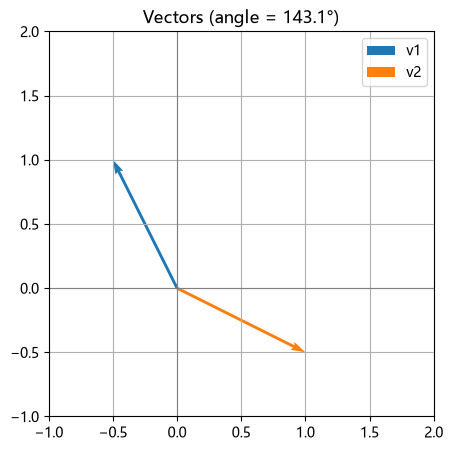

In [77]:
# 取前两个分量作为二维向量
import matplotlib.pyplot as plt
v1 = np.array([-0.5, 1])
v2 = np.array([1, -0.5])

plt.figure(figsize=(5, 5))
plt.quiver(0, 0, v1[0], v1[1], angles="xy", scale_units="xy", scale=1,
           color="C0", label="v1")
plt.quiver(0, 0, v2[0], v2[1], angles="xy", scale_units="xy", scale=1,
           color="C1", label="v2")

# 夹角
cos_theta = v1 @ v2 / (np.linalg.norm(v1) * np.linalg.norm(v2))
theta = np.degrees(np.arccos(np.clip(cos_theta, -1, 1)))
plt.title(f"Vectors (angle = {theta:.1f}°)")

# 坐标轴
plt.axhline(0, color="gray", lw=0.8)
plt.axvline(0, color="gray", lw=0.8)
plt.xlim(-1, max(v1[0], v2[0]) + 1)
plt.ylim(-1, max(v1[1], v2[1]) + 1)
plt.gca().set_aspect("equal")
plt.legend()
plt.grid(True)
plt.show()

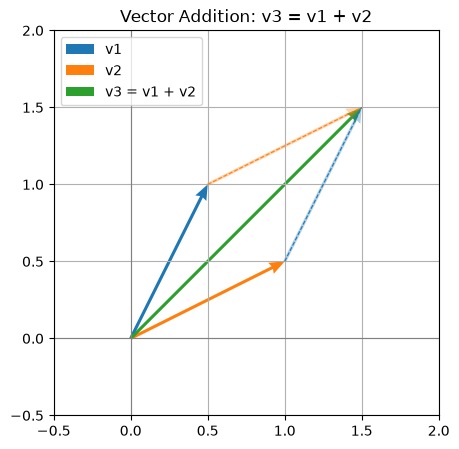

In [70]:
import numpy as np
import matplotlib.pyplot as plt

# 定义向量
v1 = np.array([0.5, 1.0])
v2 = np.array([1.0, 0.5])
v3 = v1 + v2    

fig, ax = plt.subplots(figsize=(5, 5))

def draw_vec(origin, vec, color, label=None, alpha=1.0, ls="-"):
    ax.quiver(
        origin[0], origin[1], vec[0], vec[1],
        angles="xy", scale_units="xy", scale=1,
        color=color, alpha=alpha, label=label,
        width=0.008, headwidth=4,
    )

# 1. 从原点出发的加数与和
draw_vec((0, 0), v1, "C0", "v1")
draw_vec((0, 0), v2, "C1", "v2")
draw_vec((0, 0), v3, "C2", "v3 = v1 + v2")

# 2. 首尾相接（浅色辅助展示）
draw_vec(v1, v2, "C1", alpha=0.35) # 走到 v1 终点，再画 v2
draw_vec(v2, v1, "C0", alpha=0.35) # 走到 v2 终点，再画 v1

# 3. 虚线连接，形成平行四边形
ax.plot([v1[0], v3[0]], [v1[1], v3[1]], "C1--", lw=0.8)
ax.plot([v2[0], v3[0]], [v2[1], v3[1]], "C0--", lw=0.8)

ax.set_title("Vector Addition: v3 = v1 + v2")

# 坐标轴与范围
ax.axhline(0, color="gray", lw=0.8)
ax.axvline(0, color="gray", lw=0.8)
pts = np.array([[0, 0], v1, v2, v3])
ax.set_xlim(pts[:, 0].min() - 0.5, pts[:, 0].max() + 0.5)
ax.set_ylim(pts[:, 1].min() - 0.5, pts[:, 1].max() + 0.5)
ax.set_aspect("equal")
ax.grid(True)
ax.legend(loc="upper left")

plt.show()

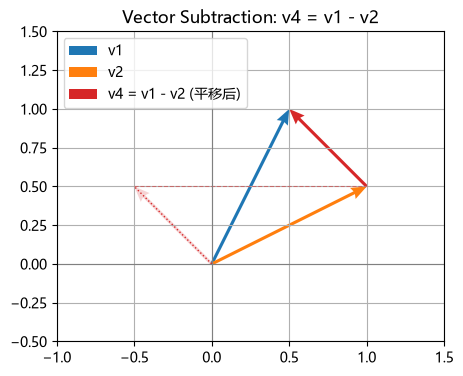

In [73]:
import numpy as np
import matplotlib.pyplot as plt
plt.rcParams['font.sans-serif'] = ['Microsoft YaHei']

# 定义向量
v1 = np.array([0.5, 1.0])
v2 = np.array([1.0, 0.5])
v4 = v1 - v2    # 即 [-0.5, 0.5]

fig, ax = plt.subplots(figsize=(5, 5))

def draw_vec(origin, vec, color, label=None, alpha=1.0):
    ax.quiver(
        origin[0], origin[1], vec[0], vec[1],
        angles="xy", scale_units="xy", scale=1,
        color=color, alpha=alpha, label=label,
        width=0.008, headwidth=4,
    )

# 1. 从原点出发的基础向量
draw_vec((0, 0), v1, "C0", "v1")
draw_vec((0, 0), v2, "C1", "v2")

# 2. 首尾相接的减法：将 v4 的起点平移到 v2 的终点
# 从 v2 终点指向 v1 终点
draw_vec(v2, v4, "C3", "v4 = v1 - v2 (平移后)")

# 3. （可选）从原点画出 v4 的原本位置，用虚线表示平移过程
draw_vec((0, 0), v4, "C3", alpha=0.2)
ax.plot([0, v4[0]], [0, v4[1]], "C3:", lw=1) # 原点处的 v4
ax.plot([v4[0], v2[0]], [v4[1], v2[1]], "C3--", lw=0.8, alpha=0.5) # 平移轨迹

ax.set_title("Vector Subtraction: v4 = v1 - v2")

# 坐标轴与范围
ax.axhline(0, color="gray", lw=0.8)
ax.axvline(0, color="gray", lw=0.8)

# 动态范围计算（包含原点、v1、v2、v4的坐标）
pts = np.array([[0, 0], v1, v2, v4])
ax.set_xlim(pts[:, 0].min() - 0.5, pts[:, 0].max() + 0.5)
ax.set_ylim(pts[:, 1].min() - 0.5, pts[:, 1].max() + 0.5)
ax.set_aspect("equal")
ax.grid(True)
ax.legend(loc="upper left")

plt.show()

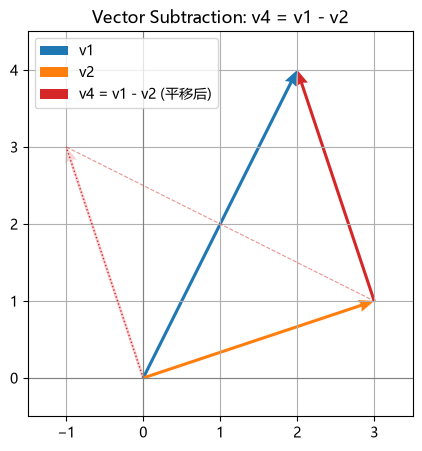

In [79]:
import numpy as np
import matplotlib.pyplot as plt
plt.rcParams['font.sans-serif'] = ['Microsoft YaHei']

# 定义向量
v1 = np.array([2, 4])
v2 = np.array([3, 1])
v4 = v1 - v2    # 即 [-0.5, 0.5]

fig, ax = plt.subplots(figsize=(5, 5))

def draw_vec(origin, vec, color, label=None, alpha=1.0):
    ax.quiver(
        origin[0], origin[1], vec[0], vec[1],
        angles="xy", scale_units="xy", scale=1,
        color=color, alpha=alpha, label=label,
        width=0.008, headwidth=4,
    )

# 1. 从原点出发的基础向量
draw_vec((0, 0), v1, "C0", "v1")
draw_vec((0, 0), v2, "C1", "v2")

# 2. 首尾相接的减法：将 v4 的起点平移到 v2 的终点
# 从 v2 终点指向 v1 终点
draw_vec(v2, v4, "C3", "v4 = v1 - v2 (平移后)")

# 3. （可选）从原点画出 v4 的原本位置，用虚线表示平移过程
draw_vec((0, 0), v4, "C3", alpha=0.2)
ax.plot([0, v4[0]], [0, v4[1]], "C3:", lw=1) # 原点处的 v4
ax.plot([v4[0], v2[0]], [v4[1], v2[1]], "C3--", lw=0.8, alpha=0.5) # 平移轨迹

ax.set_title("Vector Subtraction: v4 = v1 - v2")

# 坐标轴与范围
ax.axhline(0, color="gray", lw=0.8)
ax.axvline(0, color="gray", lw=0.8)

# 动态范围计算（包含原点、v1、v2、v4的坐标）
pts = np.array([[0, 0], v1, v2, v4])
ax.set_xlim(pts[:, 0].min() - 0.5, pts[:, 0].max() + 0.5)
ax.set_ylim(pts[:, 1].min() - 0.5, pts[:, 1].max() + 0.5)
ax.set_aspect("equal")
ax.grid(True)
ax.legend(loc="upper left")

plt.show()

In [30]:
import numpy as np

a = np.array([[1,2,3],[4,5,6]])
b = np.array([[7,8],[9,10],[11,12]])

c = a @ b

print(c)

[[ 58  64]
 [139 154]]


r = 0.4000, dt = 4.000000e-03, nt = 50


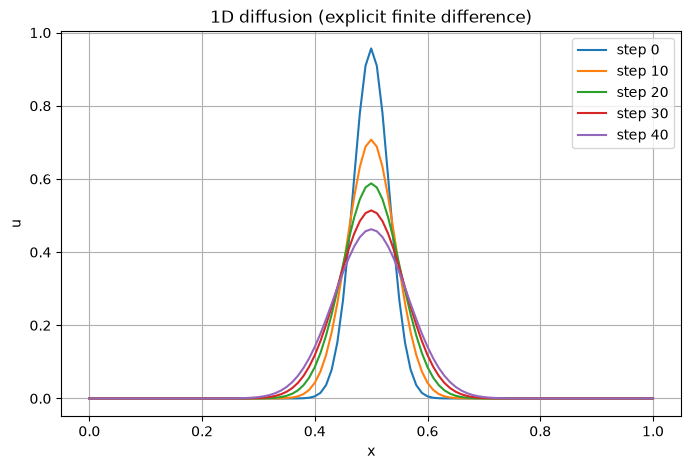

In [1]:

# 一维扩散: 显式有限差分

import numpy as np
import matplotlib.pyplot as plt

# ----------------------------
# 参数
# ----------------------------
L = 1.0          # 空间长度
T = 0.2          # 总时间
D = 0.01         # 扩散系数

nx = 101         # 空间网格点数
dx = L / (nx - 1)

# 稳定性条件：dt <= 0.5 * dx^2 / D
dt = 0.4 * dx**2 / D
nt = int(T / dt)

x = np.linspace(0, L, nx)

# 初始条件：中间一个高斯分布
u = np.exp(-((x - 0.5) ** 2) / (2 * 0.03**2))

# 边界条件：两端固定为 0
u[0] = 0.0
u[-1] = 0.0

# ----------------------------
# 时间推进
# ----------------------------
r = D * dt / dx**2
print(f"r = {r:.4f}, dt = {dt:.6e}, nt = {nt}")

snapshots = []
save_every = max(1, nt // 5)

for n in range(nt):
    # 中心差分，注意用旧值 u 计算新值
    u_new = u.copy()
    u_new[1:-1] = u[1:-1] + r * (u[2:] - 2 * u[1:-1] + u[:-2])

    # 边界条件
    u_new[0] = 0.0
    u_new[-1] = 0.0

    u = u_new

    if n % save_every == 0:
        snapshots.append(u.copy())

# ----------------------------
# 可视化
# ----------------------------
plt.figure(figsize=(8, 5))
for i, snap in enumerate(snapshots):
    plt.plot(x, snap, label=f"step {i * save_every}")
plt.xlabel("x")
plt.ylabel("u")
plt.title("1D diffusion (explicit finite difference)")
plt.legend()
plt.grid(True)
plt.show()

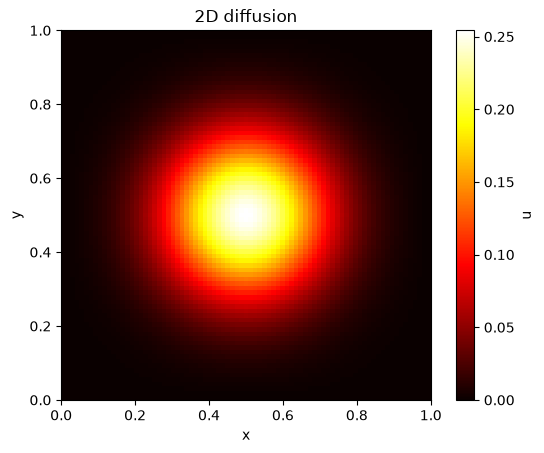

In [23]:
# 二维扩散简版

import numpy as np
import matplotlib.pyplot as plt

nx, ny = 81, 81
Lx, Ly = 1.0, 1.0
dx = Lx / (nx - 1)
dy = Ly / (ny - 1)
D = 0.01

dt = 0.2 * dx**2 / D       # 满足 r <= 0.25
nt = 300

x = np.linspace(0, Lx, nx)
y = np.linspace(0, Ly, ny)
X, Y = np.meshgrid(x, y)

# 初始条件：中心一个高斯斑
u = np.exp(-((X - 0.5)**2 + (Y - 0.5)**2) / (2 * 0.08**2))

r = D * dt / dx**2

for n in range(nt):
    u_new = u.copy()
    u_new[1:-1, 1:-1] = u[1:-1, 1:-1] + r * (
        u[2:, 1:-1] + u[:-2, 1:-1] +
        u[1:-1, 2:] + u[1:-1, :-2] -
        4 * u[1:-1, 1:-1]
    )
    u_new[0, :] = 0
    u_new[-1, :] = 0
    u_new[:, 0] = 0
    u_new[:, -1] = 0
    u = u_new

plt.imshow(u, extent=[0, Lx, 0, Ly], origin="lower", cmap="hot")
plt.colorbar(label="u")
plt.title("2D diffusion")
plt.xlabel("x")
plt.ylabel("y")
plt.show()

r = 0.1500 (需要 <= 1/6 ≈ 0.1667)
dt = 9.375000e-03, nt = 5


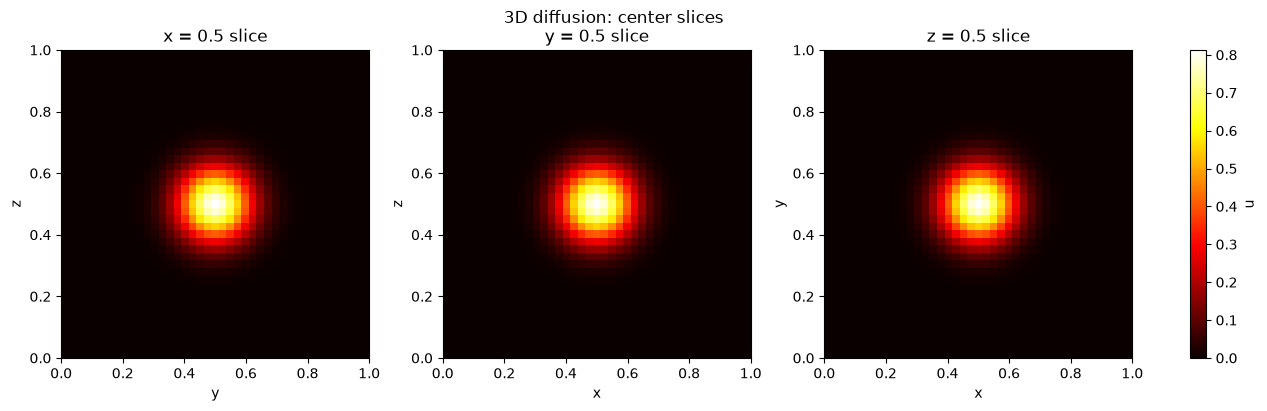

In [24]:
import numpy as np
import matplotlib.pyplot as plt

# ----------------------------
# 参数
# ----------------------------
L = 1.0
T = 0.05
D = 0.01

nx, ny, nz = 41, 41, 41
dx = L / (nx - 1)
dy = L / (ny - 1)
dz = L / (nz - 1)

# 三维显式格式稳定性：r <= 1/6
dt = 0.15 * dx**2 / D
nt = int(T / dt)

x = np.linspace(0, L, nx)
y = np.linspace(0, L, ny)
z = np.linspace(0, L, nz)
X, Y, Z = np.meshgrid(x, y, z, indexing="ij")

# 初始条件：中心三维高斯
u = np.exp(
    -((X - 0.5)**2 + (Y - 0.5)**2 + (Z - 0.5)**2)
    / (2 * 0.08**2)
)

# 边界固定为 0
u[0, :, :] = u[-1, :, :] = 0
u[:, 0, :] = u[:, -1, :] = 0
u[:, :, 0] = u[:, :, -1] = 0

r = D * dt / dx**2
print(f"r = {r:.4f} (需要 <= 1/6 ≈ 0.1667)")
print(f"dt = {dt:.6e}, nt = {nt}")

# ----------------------------
# 时间推进
# ----------------------------
for n in range(nt):
    u_new = u.copy()

    u_new[1:-1, 1:-1, 1:-1] = u[1:-1, 1:-1, 1:-1] + r * (
        u[2:,   1:-1, 1:-1] + u[:-2,  1:-1, 1:-1] +
        u[1:-1, 2:,   1:-1] + u[1:-1, :-2,  1:-1] +
        u[1:-1, 1:-1, 2:]   + u[1:-1, 1:-1, :-2] -
        6 * u[1:-1, 1:-1, 1:-1]
    )

    # 边界
    u_new[0, :, :] = u_new[-1, :, :] = 0
    u_new[:, 0, :] = u_new[:, -1, :] = 0
    u_new[:, :, 0] = u_new[:, :, -1] = 0

    u = u_new

# ----------------------------
# 可视化：三个中心正交切片
# ----------------------------
mid = nx // 2

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

im0 = axes[0].imshow(u[mid, :, :].T, origin="lower",
                     extent=[0, L, 0, L], cmap="hot")
axes[0].set_title("x = 0.5 slice")
axes[0].set_xlabel("y")
axes[0].set_ylabel("z")

im1 = axes[1].imshow(u[:, mid, :].T, origin="lower",
                     extent=[0, L, 0, L], cmap="hot")
axes[1].set_title("y = 0.5 slice")
axes[1].set_xlabel("x")
axes[1].set_ylabel("z")

im2 = axes[2].imshow(u[:, :, mid].T, origin="lower",
                     extent=[0, L, 0, L], cmap="hot")
axes[2].set_title("z = 0.5 slice")
axes[2].set_xlabel("x")
axes[2].set_ylabel("y")

for ax in axes:
    ax.set_aspect("equal")

fig.colorbar(im2, ax=axes, fraction=0.02, label="u")
plt.suptitle("3D diffusion: center slices")
plt.show()

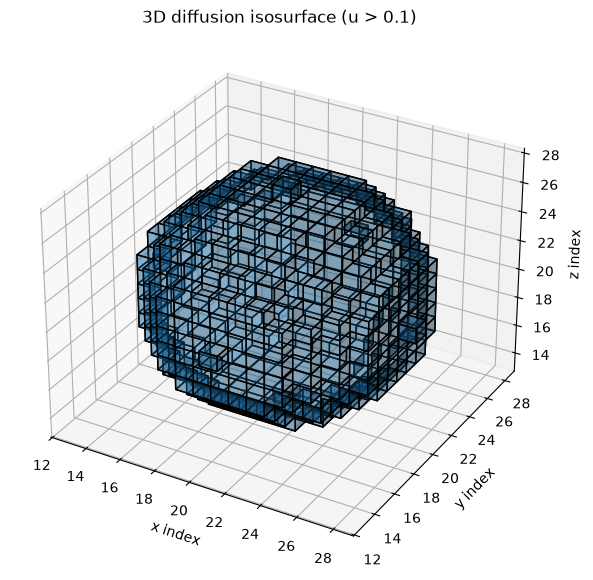

In [25]:
fig = plt.figure(figsize=(7, 7))
ax = fig.add_subplot(111, projection="3d")

threshold = 0.1
vox = u > threshold

ax.voxels(vox, edgecolor="k", alpha=0.3)
ax.set_xlabel("x index")
ax.set_ylabel("y index")
ax.set_zlabel("z index")
ax.set_title(f"3D diffusion isosurface (u > {threshold})")
plt.show()

In [81]:
# %pip install scipy

import numpy as np
from scipy.integrate import quad

def laplace_numerical(f, s, t_max=np.inf):
    """
    数值计算拉普拉斯变换
    f: 函数 f(t)
    s: 复数 s = sigma + jw
    """
    # 构造被积函数: f(t) * e^(-s*t)
    integrand = lambda t: f(t) * np.exp(-s * t)
    
    # 分别对实部和虚部积分
    real_part, _ = quad(lambda t: integrand(t).real, 0, t_max)
    imag_part, _ = quad(lambda t: integrand(t).imag, 0, t_max)
    
    return real_part + 1j * imag_part

# 测试：f(t) = e^(-2t)
f_t = lambda t: np.exp(-2 * t)

# 计算 s = 1 + 1j 处的值
s_val = 1 + 1j
F_val = laplace_numerical(f_t, s_val)
print(f"在 s = {s_val} 处，F(s) = {F_val:.4f}")

# 理论值应为 1/(s+2) = 1/(3+1j) = 0.3 - 0.1j
print(f"理论值：{1 / (s_val + 2):.4f}")

在 s = (1+1j) 处，F(s) = 0.3000-0.1000j
理论值：0.3000-0.1000j


In [ ]:
# %pip install numexpr

# NumPy 的瓶颈：中间数组：
# 当你执行 result = 3*a + 4*b 时，NumPy 会先计算 3*a 并生成一个临时数组，
# 再计算 4*b 生成另一个，最后将它们相加。对于大数组，这些中间数组会消耗大量内存并拖慢速度。

# Numexpr 的优化：分块计算：numexpr 将表达式作为一个整体，
# 将大数组切分成适合 CPU 缓存（L1 Cache）的小块（chunk），然后在块上直接完成所有运算，避免了创建完整的中间数组

# numexpr 并非万能，最佳适用场景如下：
# 处理大型数组：当数组大到无法完全放入 CPU 缓存（L1 Cache）时，优化效果最明显。
# 复杂的数学表达式：包含多个运算符和函数的“长”表达式，是 numexpr 发挥优势的主场。
# 内存敏感的应用：当创建大型临时数组会导致内存不足或频繁的垃圾回收时。
# 希望利用多核：numexpr 的自动多线程能充分利用多核 CPU 的性能。
# 反之，以下情况继续使用 NumPy 即可：对简单表达式（如 a+b）的计算；对小型数组的操作；以及代码中非计算密集的部分。

import numpy as np
import numexpr as ne

# 创建大型数组
a = np.arange(1e7)
b = np.arange(1e7)

# NumPy 方式
result_numpy = 3 * a + 4 * b
print(result_numpy)

# Numexpr 方式 (使用字符串表达式)
result_numexpr = ne.evaluate("3 * a + 4 * b")
print(result_numexpr)

[0.0000000e+00 7.0000000e+00 1.4000000e+01 ... 6.9999979e+07 6.9999986e+07
 6.9999993e+07]
[0.0000000e+00 7.0000000e+00 1.4000000e+01 ... 6.9999979e+07 6.9999986e+07
 6.9999993e+07]


In [ ]:
# NumPy = 高性能多维数组 + 向量化数学运算 + 线性代数工具
# Pandas 则在 NumPy 的基础上，提供了处理表格数据（如 Excel、CSV）的高级、便捷的接口。
# Matplotlib：直接接受 NumPy 数组进行绘图
# SciPy：基于 NumPy 构建的高级科学计算（优化、积分、信号处理）。
# Scikit-learn：机器学习库，输入输出均为 NumPy 数组。
# PyTorch / TensorFlow：深度学习框架，其 API 设计与 NumPy 高度相似，且常与 NumPy 互相转换。

# 做数学、算矩阵、搞科研 → NumPy
# 做报表、洗数据、算业务 → Pandas